# Q2 — La météo explique-t-elle tout ? (exploration)

**Objectif :** avant tout modèle, regarder comment le nombre de trajets varie selon trois groupes de facteurs, pour voir lequel fait le plus varier l'usage :

1. **Météo** : pluie oui/non, température par tranches de 5 °C ;
2. **Jour et heure** : semaine ou week-end, heure de départ ;
3. **Emplacement** : `type_quartier` de la station de départ (jointure avec les stations).

**Unité de comptage : le créneau (jour × heure).** Les trajets n'ont pas de date, seulement un jour (lun…dim) et une heure. On compte donc les trajets par créneau, puis on fait la moyenne de ces comptes selon chaque facteur. Un total brut serait trompeur (la semaine compte 5 jours, le week-end 2).

- 7 jours × 19 heures (5 h – 23 h) = **133 créneaux**. Aucun trajet n'a lieu entre 0 h et 4 h, ces heures sont donc exclues.
- Les combinaisons sans aucun trajet sont **comptées à 0**, sinon les moyennes seraient surestimées.
- C'est aussi la variable que l'on modélisera ensuite en régression : le nombre de trajets par créneau.

## 1. Chargement des données nettoyées

In [ ]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("../src")
from data_loader import get_prepared_dataset

df_stations, df_trajets, _ = get_prepared_dataset()

# Jointure : type de quartier de la station de départ
df = df_trajets.merge(
    df_stations[["station_id", "type_quartier"]],
    left_on="station_depart",
    right_on="station_id",
    how="left",
)

print("Trajets :", df.shape[0], "| sans type de quartier après jointure :", df["type_quartier"].isna().sum())

Trajets : 697 | sans type de quartier après jointure : 0


In [ ]:
JOURS = ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
HEURES = list(range(5, 24))
WEEK_END = ["sam", "dim"]

# Style des graphiques : une seule série par graphique, donc une seule couleur
COULEUR = "#2a78d6"
TEXTE_SECONDAIRE = "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c3",
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#e6e5e1",
    "axes.axisbelow": True,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelcolor": TEXTE_SECONDAIRE,
    "xtick.color": TEXTE_SECONDAIRE,
    "ytick.color": TEXTE_SECONDAIRE,
})


def comptage_par_creneau(df, facteur=None, modalites=None):
    """Nombre de trajets par créneau (jour × heure), éventuellement croisé avec un facteur.
    Les combinaisons sans aucun trajet sont comptées à 0."""
    cles = ["jour", "heure"] + ([facteur] if facteur else [])
    niveaux = [JOURS, HEURES] + ([modalites] if facteur else [])
    grille = pd.MultiIndex.from_product(niveaux, names=cles)
    return (
        df.groupby(cles, observed=True).size()
        .reindex(grille, fill_value=0)
        .rename("nb_trajets")
        .reset_index()
    )


def barres(moyennes, titre, xlabel, ylabel="Trajets moyens par créneau", fichier=None, etiquettes=True, decimales=2):
    """Diagramme en barres simple des moyennes ; enregistré dans outputs/figures/ si `fichier`."""
    fig, ax = plt.subplots(figsize=(7, 4))
    rects = ax.bar(moyennes.index.astype(str), moyennes.values, color=COULEUR, width=0.6)
    if etiquettes:
        ax.bar_label(rects, fmt=f"%.{decimales}f", padding=3, color=TEXTE_SECONDAIRE, fontsize=9)
    ax.set_title(titre, loc="left")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.margins(y=0.12)
    fig.tight_layout()
    if fichier:
        fig.savefig(f"../outputs/figures/{fichier}", dpi=150, bbox_inches="tight")
    plt.show()


def resume(comptages, facteur, colonne="nb_trajets", ordre=None):
    """Comptage moyen par créneau (et nombre total de trajets) pour chaque modalité, dans l'ordre `ordre`."""
    tableau = comptages.groupby(facteur)[colonne].agg(moyenne="mean", total="sum")
    return tableau.reindex(ordre) if ordre is not None else tableau

## 2. Météo

### 2.1 Pluie

In [3]:
c_pluie = comptage_par_creneau(df, "pluie", ["non", "oui"])
moy_pluie = resume(c_pluie, "pluie")
moy_pluie.round(2)

,moyenne,total
pluie,,
non,4.00,532
oui,1.24,165


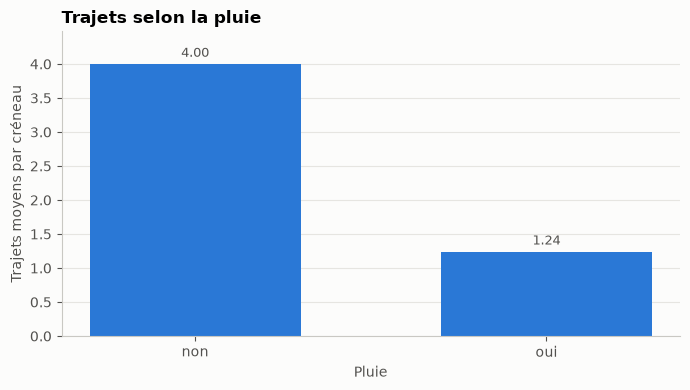

In [4]:
barres(moy_pluie["moyenne"], "Trajets selon la pluie", "Pluie", fichier="q2_pluie.png")

> ⚠️ **Limite :** sans date, on ne sait pas combien de créneaux ont été pluvieux. Une moyenne plus basse sous la pluie peut venir de ce que les gens roulent moins quand il pleut, **ou** simplement de ce qu'il pleut moins souvent qu'il ne fait sec. Les deux effets sont mélangés. Même limite pour la température.

### 2.2 Température (tranches de 5 °C)

In [5]:
TRANCHES = ["< 5 °C", "5–10 °C", "10–15 °C", "15–20 °C", "20–25 °C", "≥ 25 °C"]
df["tranche_temperature"] = pd.cut(
    df["temperature_c"], bins=[-np.inf, 5, 10, 15, 20, 25, np.inf], labels=TRANCHES, right=False
)

c_temp = comptage_par_creneau(df, "tranche_temperature", TRANCHES)
moy_temp = resume(c_temp, "tranche_temperature", ordre=TRANCHES)
moy_temp.round(2)

,moyenne,total
tranche_temperature,,
< 5 °C,0.49,65
5–10 °C,0.87,116
10–15 °C,1.53,203
15–20 °C,1.23,163
20–25 °C,0.84,112
≥ 25 °C,0.29,38


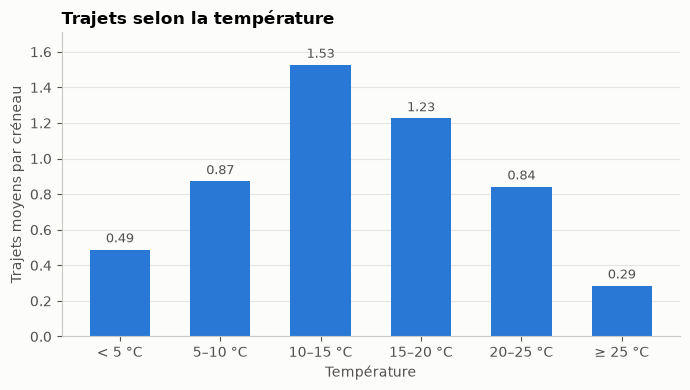

In [6]:
barres(moy_temp["moyenne"], "Trajets selon la température", "Température", fichier="q2_temperature.png")

## 3. Jour et heure

### 3.1 Semaine ou week-end

In [7]:
c_base = comptage_par_creneau(df)  # 133 créneaux jour × heure
c_base["periode"] = np.where(c_base["jour"].isin(WEEK_END), "week-end", "semaine")

moy_periode = resume(c_base, "periode")
moy_periode.round(2)

,moyenne,total
periode,,
semaine,5.86,557
week-end,3.68,140


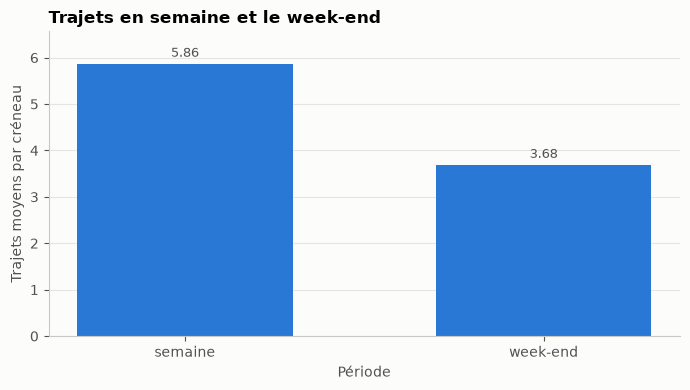

In [8]:
barres(moy_periode["moyenne"], "Trajets en semaine et le week-end", "Période", fichier="q2_semaine_weekend.png")

### 3.2 Heure de départ

In [9]:
moy_heure = resume(c_base, "heure")
moy_heure.round(2).T

heure,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
moyenne,1.14,3.29,7.29,8.71,7.29,3.71,3.57,5.71,5.0,6.71,7.86,10.57,8.57,6.71,4.57,3.86,2.29,1.43,1.29
total,8.00,23.00,51.00,61.00,51.00,26.00,25.00,40.00,35.0,47.00,55.00,74.00,60.00,47.00,32.00,27.00,16.00,10.00,9.00


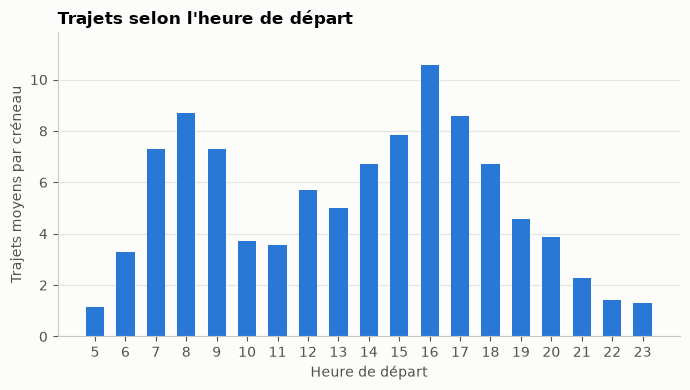

In [10]:
barres(
    moy_heure["moyenne"], "Trajets selon l'heure de départ", "Heure de départ",
    fichier="q2_heure.png", etiquettes=False,
)

## 4. Emplacement : type de quartier de la station de départ

Les types de quartier n'ont pas le même nombre de stations (51 stations `bureaux` contre 21 `gare`). Pour comparer à armes égales, on divise le comptage par le nombre de stations du type : on obtient des **trajets moyens par station et par créneau**.

In [11]:
QUARTIERS = sorted(df_stations["type_quartier"].unique())
nb_stations = df_stations["type_quartier"].value_counts()

c_quartier = comptage_par_creneau(df, "type_quartier", QUARTIERS)
c_quartier["par_station"] = c_quartier["nb_trajets"] / c_quartier["type_quartier"].map(nb_stations)

moy_quartier = resume(c_quartier, "type_quartier", colonne="par_station")
moy_quartier["total"] = c_quartier.groupby("type_quartier")["nb_trajets"].sum()
moy_quartier["nb_stations"] = nb_stations
moy_quartier.round(3)

,moyenne,total,nb_stations
type_quartier,,,
bureaux,0.040,274,51
gare,0.033,91,21
résidentiel,0.034,177,39
université,0.040,155,29


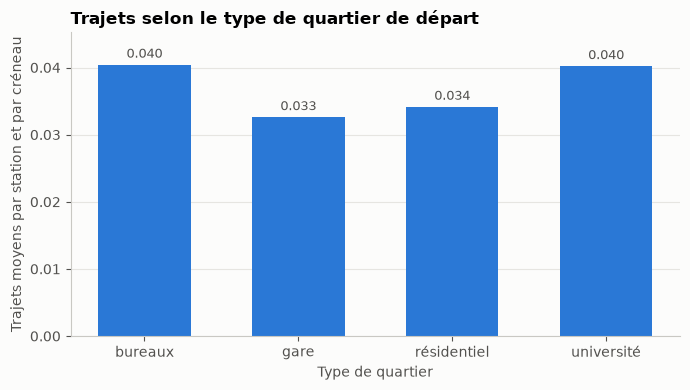

In [12]:
barres(
    moy_quartier["moyenne"], "Trajets selon le type de quartier de départ", "Type de quartier",
    ylabel="Trajets moyens par station et par créneau", fichier="q2_quartier.png", decimales=3,
)

## 5. Synthèse : quel facteur fait le plus varier l'usage ?

Pour chaque facteur, on compare la modalité la moins et la plus fréquentée. Le **rapport max / min** ne dépend pas de l'unité (par créneau ou par station) et permet donc de comparer les facteurs entre eux.

In [13]:
facteurs = {
    "Météo — pluie": moy_pluie["moyenne"],
    "Météo — température": moy_temp["moyenne"],
    "Temps — semaine / week-end": moy_periode["moyenne"],
    "Temps — heure de départ": moy_heure["moyenne"],
    "Emplacement — type de quartier": moy_quartier["moyenne"],
}

synthese = pd.DataFrame([
    {
        "facteur": nom,
        "nb_modalites": len(m),
        "modalite_min": m.idxmin(),
        "moyenne_min": m.min(),
        "modalite_max": m.idxmax(),
        "moyenne_max": m.max(),
        "rapport_max_min": m.max() / m.min(),
    }
    for nom, m in facteurs.items()
]).sort_values("rapport_max_min", ascending=False).set_index("facteur")

synthese.round(3)

,nb_modalites,modalite_min,moyenne_min,modalite_max,moyenne_max,rapport_max_min
facteur,,,,,,
Temps — heure de départ,19,5,1.143,16,10.571,9.250
Météo — température,6,≥ 25 °C,0.286,10–15 °C,1.526,5.342
Météo — pluie,2,oui,1.241,non,4.000,3.224
Temps — semaine / week-end,2,week-end,3.684,semaine,5.863,1.591
Emplacement — type de quartier,4,gare,0.033,bureaux,0.040,1.240


> Le rapport max / min augmente mécaniquement avec le nombre de modalités : l'heure en a 19, la pluie 2. On le lit donc comme un ordre de grandeur, à compléter par la forme des graphiques.